In [1]:
import os, sys, shutil
from tqdm import tqdm
import numpy as np
import pandas as pd
# Set the display options to show all columns
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
from PIL import Image
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import math
import random
from datetime import datetime
from scipy.stats import binomtest
from collections import defaultdict
experiment_version = 1
response_version = 1

stimuli_path = f"stimuli_v{experiment_version}/"
response_path = f"responses_v{experiment_version}/"
dataframe_path = f"dataframes_v{experiment_version}/"

os.makedirs(stimuli_path, exist_ok=True)
os.makedirs(response_path, exist_ok=True)
os.makedirs(dataframe_path, exist_ok=True)

# CREATE EXPERIMENT DATAFRAME AND TRIAL FILES FOR MEADOWS

In [40]:

#Experiment column key:
# 1: Experiment 1, GT experiment to compare 2AFC scores of recons with varying strength parameters
df_exp = pd.DataFrame(columns=["experiment", "stim1", "stim2", "stim3", "strength", "target_on_left", "method", "catch_trial", "sample", "subject",  "rep", "mode", "stimtype"])
i=0
stimuli_root = "/export/raid1/home/kneel027/nsd_imagery_journal_paper/reconstructions/"
gt_root = "/export/raid1/home/kneel027/data/umn-imagery/nsddata_stimuli/stimuli/imagery_images/"
method = "braindiffuser_augmentations"
mode="gt"
for sample in tqdm(range(18)):
    gt_sample = f"{sample}_ground_truth"
    gt_sample_path = f"{gt_root}/{sample}.png"
    gt_image = Image.open(gt_sample_path).resize((512,512))
    gt_image.save(f"stimuli_v{experiment_version}/{gt_sample}.png")
    
    if sample < 6:
        stimtype = "simple"
    elif sample < 12:
        stimtype = "complex"
    else:
        stimtype = "concept"
    
    for rep in range(10):
        for strength in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
            # Experiment 1, shuffle VDVAE
            correct_recon = f"{sample}_gt_recon_{rep}_{strength}"
            incorrect_recon = f"{sample}_gt_recon_{rep}_{strength}_sv"
        
            # Load the stimulus images and save as pngs to stimuli folder
            correct_recon_path = f"{stimuli_root}vision/{method}/{strength:.1f}-str_1.0-mix_gt/subject1/{sample}/{rep}.png"
            incorrect_recon_path = f"{stimuli_root}vision/{method}/{strength:.1f}-str_1.0-mix_gt_shuffle-vdvae_same-dist/subject1/{sample}/{rep}.png"
            # Copy the stimulus images to the stimuli folder
            shutil.copy(correct_recon_path, f"stimuli_v{experiment_version}/{correct_recon}.png")
            shutil.copy(incorrect_recon_path, f"stimuli_v{experiment_version}/{incorrect_recon}.png")
            # Configure stimuli names and order in experiment dataframe
            order = random.randrange(2)
            sample_names = [correct_recon, incorrect_recon]
            left_sample = sample_names.pop(order)
            right_sample = sample_names.pop()
            
            df_exp.loc[i] = {"experiment" : 1, "stim1" : gt_sample, "stim2" : left_sample, "stim3" : right_sample, "sample" : sample, "subject" : "gt", "strength" : strength, "target_on_left" : order == 0, "method" : method, "catch_trial" : None, "rep" : rep, "mode" : mode, "stimtype" : stimtype, "trial_rep" : 0}
            i+=1
            # Experiment 2: shuffle CLIP-Text
            correct_recon = f"{sample}_gt_recon_{rep}_{strength}"
            incorrect_recon = f"{sample}_gt_recon_{rep}_{strength}_sc"
        
            # Load the stimulus images and save as pngs to stimuli folder
            correct_recon_path = f"{stimuli_root}vision/{method}/{strength:.1f}-str_1.0-mix_gt/subject1/{sample}/{rep}.png"
            incorrect_recon_path = f"{stimuli_root}vision/{method}/{strength:.1f}-str_1.0-mix_gt_shuffle-clip/subject1/{sample}/{rep}.png"
            # Copy the stimulus images to the stimuli folder
            # shutil.copy(correct_recon_path, f"stimuli_v{experiment_version}/{correct_recon}.png")
            # shutil.copy(incorrect_recon_path, f"stimuli_v{experiment_version}/{incorrect_recon}.png")
            # Configure stimuli names and order in experiment dataframe
            order = random.randrange(2)
            sample_names = [correct_recon, incorrect_recon]
            left_sample = sample_names.pop(order)
            right_sample = sample_names.pop()
            
            df_exp.loc[i] = {"experiment" : 2, "stim1" : gt_sample, "stim2" : left_sample, "stim3" : right_sample, "sample" : sample, "subject" : "gt", "strength" : strength, "target_on_left" : order == 0, "method" : method, "catch_trial" : None, "rep" : rep, "mode" : mode, "stimtype" : stimtype, "trial_rep" : 0}
            i+=1
df_exp = df_exp.sample(frac=1)
print(len(df_exp))


100%|██████████| 18/18 [00:17<00:00,  1.03it/s]

3960


In [45]:
# Check if all images are present in final stimuli folder
count_not_found = 0
stim_path = f"stimuli_v{experiment_version}/"
for index, row in df_exp.iterrows():
    if not (os.path.exists(f"{stim_path}{row['stim1']}.png")):
        print(f"{row['stim1']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim2']}.png")):
        print(f"{row['stim2']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim3']}.png")):
        print(f"{row['stim3']}.png")
        count_not_found += 1
print(count_not_found)

0


### Add pID columns to assign trials to different participants

In [42]:
# Shuffle Experiment 1
df_exp1 = df_exp.sample(frac=1, random_state=42)
# Calculate the number of participants needed
exp1_trials_per_participant = 42
num_participants = len(df_exp1) // exp1_trials_per_participant

# Assign pID for Experiment 1
df_exp1['pID'] = [i % num_participants for i in range(len(df_exp1))]

# Combine and shuffle the dataframe to mix up the trials across all experiments
df_exp_pid = df_exp1

# Sort by pID to ensure the dataframe is ordered by participant, facilitating even distribution
df_exp_pid.sort_values(by='pID', inplace=True)

# Ensure pID is the first column
cols = list(df_exp_pid.columns)
cols.insert(0, cols.pop(cols.index('pID')))
df_exp_pid = df_exp_pid[cols]
print(num_participants)

94


In [43]:
#Add catch trials within each pID section
df_exp_catch = df_exp_pid.copy()
for pID in np.unique(df_exp_catch['pID']):
    df_pid = df_exp_catch[(df_exp_catch['pID'] == pID)]
    # Ground truth catch trials
    try:
        gt_catch_trials = df_pid.sample(n=8)
    except:
        print(pID, df_pid)
    gt_catch_trials['catch_trial'] = "ground_truth"
    for index, row in gt_catch_trials.iterrows():
        
        order = random.randrange(2)
        ground_truth = row['stim1']
        stims = [ground_truth, row['stim2']]
        
        gt_catch_trials.at[index, 'stim2'] = stims.pop(order)
        gt_catch_trials.at[index, 'stim3'] = stims.pop()
        # Target on left here means the ground truth repeat is on the left
        gt_catch_trials.at[index, 'target_on_left'] = (order == 0)
    df_exp_catch = pd.concat([df_exp_catch, gt_catch_trials])
#shuffle catch trials into the sessions
df_exp_catch = df_exp_catch.sample(frac=1).sort_values(by='pID', kind='mergesort')
print(len(df_exp_catch))
print(len(df_exp_catch[(df_exp_catch['pID'] == 0)]))
print(len(np.unique(df_exp_catch['pID'])))
print(len(df_exp_catch[df_exp_catch['experiment'] == 1]))
# print(len(df_exp_catch[df_exp_catch['experiment'].isin([2, 3])]))

4712
51
94
2373


### Save experiment dataframe and tsv files

In [44]:

df_exp_catch.to_csv(f'dataframes_v{experiment_version}/experiment_v{experiment_version}.csv', index=False)

df_exp_tsv = df_exp_catch[['pID', 'stim1', 'stim2', 'stim3']].copy()
df_exp_tsv.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}.tsv", sep="\t", index=False, header=False) 

# THE FOLLOWING CELLS ARE FOR PROCESSING RESPONSES

In [55]:
df_experiment = pd.read_csv(dataframe_path + f"experiment_v{experiment_version}.csv")

df_responses = pd.read_csv(f"{response_path}annotations_v{response_version}.csv")

### Parse the responses and associate them with the trials in the experiment dataframe, to have all information available in one dataframe

In [56]:

# Initialize a list to hold row dictionaries before creating the final dataframe
rows_list = []
df_2afc = df_responses[df_responses["task"] == "2AFC"]
# Parse trials in 2AFC experiment
for index, row in tqdm(df_2afc.iterrows()):
    if row['label'] == row['stim2_id']:
        picked_left = True
    elif row['label'] == row['stim3_id']:
        picked_left = False
    else:
        print("Error")
        break
    start_timestamp = row['time_trial_start']
    end_timestamp = row['time_trial_response']
    start = datetime.fromisoformat(start_timestamp.replace("Z", "+00:00"))
    end = datetime.fromisoformat(end_timestamp.replace("Z", "+00:00"))
    # Calculate the difference in seconds
    response_time = (end - start).total_seconds()
    
    experiment_row = df_experiment[(df_experiment['stim1'] == row['stim1_name']) & (df_experiment['stim2'] == row['stim2_name']) & (df_experiment['stim3'] == row['stim3_name'])].iloc[0]
    
    if experiment_row['target_on_left']:
        strength = experiment_row['stim2'].split("_")[-1]
    else:
        strength = experiment_row['stim3'].split("_")[-1]
    
    
    row_data = {
        **experiment_row.to_dict(),
        "strength" : strength,
        "picked_left": picked_left,
        "picked_target": picked_left == experiment_row['target_on_left'],
        "participant": row['participation'],
        "response_time": response_time,
    }
    
    rows_list.append(row_data)

# Create the final dataframe from the list of row dictionaries
df_trial_combined = pd.DataFrame(rows_list)

# Dropping the extra index columns added from the experiment_row.to_dict() conversion
df_trial = df_trial_combined.drop(columns=[col for col in df_trial_combined.columns if 'Unnamed' in col])

print(df_trial.head())

4461it [00:06, 707.56it/s]

   pID  experiment            stim1                 stim2  \
0    0           1  17_ground_truth     17_gt_recon_5_0.7   
1    0           2   9_ground_truth      9_gt_recon_1_0.2   
2    0           2  11_ground_truth  11_gt_recon_7_0.8_sc   
3    0           2  13_ground_truth  13_gt_recon_7_0.9_sc   
4    0           1   7_ground_truth      7_gt_recon_3_0.4   

                  stim3 strength  target_on_left                       method  \
0  17_gt_recon_5_0.7_sv      0.7            True  braindiffuser_augmentations   
1   9_gt_recon_1_0.2_sc      0.2            True  braindiffuser_augmentations   
2     11_gt_recon_7_0.8      0.8           False  braindiffuser_augmentations   
3     13_gt_recon_7_0.9      0.9           False  braindiffuser_augmentations   
4   7_gt_recon_3_0.4_sv      0.4            True  braindiffuser_augmentations   

  catch_trial  sample subject  rep mode stimtype  picked_left  picked_target  \
0         NaN      17      gt    5   gt  concept         True     

### Find trials that didn't get completed in the previous round of the experiment, and save new trial files for another round

In [49]:
# Initialize a dictionary to count processed trials per pID
processed_trials_count = defaultdict(int)

# Your existing processing loop goes here...
# Update processed_trials_count for each row processed
for index, row_data in df_trial.iterrows():
    processed_trials_count[row_data['pID']] += 1

# Count expected trials per pID from df_experiment
expected_trials_count = df_experiment['pID'].value_counts().to_dict()

# Find pIDs with missing trials by comparing processed and expected counts
missing_trials_pids = {pID: expected_trials_count[pID] - processed_trials_count[pID] 
                       for pID in expected_trials_count 
                       if pID not in processed_trials_count or processed_trials_count[pID] < expected_trials_count[pID]-2}

# Print or handle pIDs with missing trials as needed
print(f"missing {len(missing_trials_pids.values())} pIDs")
for pID, missing_count in missing_trials_pids.items():
    print(f"pID: {pID} has {missing_count} missing trials.")
    
if len(missing_trials_pids.values()) > 0:
    df_exp_missing = df_experiment[df_experiment['pID'].isin(missing_trials_pids.keys())]

    df_catch_exp1_missing = df_exp_missing[df_exp_missing['experiment'] == 1]
    df_catch_exp23_missing = df_exp_missing[df_exp_missing['experiment'].isin([2, 3])]


    df_exp_tsv1_missing = df_catch_exp1_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv23_missing = df_catch_exp23_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv1_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp1_missing.tsv", sep="\t", index=False, header=False) 
    df_exp_tsv23_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp23_missing.tsv", sep="\t", index=False, header=False) 

missing 79 pIDs
pID: 7 has 51 missing trials.
pID: 9 has 51 missing trials.
pID: 8 has 51 missing trials.
pID: 6 has 51 missing trials.
pID: 4 has 51 missing trials.
pID: 3 has 51 missing trials.
pID: 5 has 51 missing trials.
pID: 63 has 50 missing trials.
pID: 71 has 50 missing trials.
pID: 70 has 50 missing trials.
pID: 69 has 50 missing trials.
pID: 68 has 50 missing trials.
pID: 67 has 50 missing trials.
pID: 66 has 50 missing trials.
pID: 65 has 50 missing trials.
pID: 64 has 50 missing trials.
pID: 61 has 50 missing trials.
pID: 62 has 50 missing trials.
pID: 60 has 50 missing trials.
pID: 59 has 50 missing trials.
pID: 58 has 50 missing trials.
pID: 73 has 50 missing trials.
pID: 57 has 50 missing trials.
pID: 56 has 50 missing trials.
pID: 55 has 50 missing trials.
pID: 72 has 50 missing trials.
pID: 78 has 50 missing trials.
pID: 74 has 50 missing trials.
pID: 75 has 50 missing trials.
pID: 92 has 50 missing trials.
pID: 91 has 50 missing trials.
pID: 90 has 50 missing trials.

### Parse and remove participants that failed at least 2 catch trials

In [58]:
# number of participants
print("Total participants:", len(df_trial["participant"].unique()))
gt_failures = df_trial[(df_trial['catch_trial'] == 'ground_truth') & (df_trial['picked_target'] == False)].groupby('participant').size()
# print(df_trial[(df_trial['catch_trial'] == 'ground_truth')])
# Identify participants who failed more than 1 ground truth catch trial
participants_to_remove_rule1 = gt_failures[gt_failures > 1].index.tolist()
print("Participants to remove 1:", participants_to_remove_rule1)

# Remove participants who failed the repeat catch trial, and gave different responses for identical trials
# repeat_trials = df_trial[df_trial['rep'] > 0]
# grouped_repeat_trials = repeat_trials.groupby(['stim1', 'stim2', 'stim3'])
# participant_failures = {}
# # Iterate through groups to check consistency in "picked_target" across repetitions
# for _, group in grouped_repeat_trials:
#     if group['picked_target'].nunique() != 1:  # Inconsistent "picked_target" within the group
#         for participant in group['participant'].unique(): 
#             participant_failures[participant] = participant_failures.get(participant, 0) + 1

# # Identify participants who failed at least one set of trial repetitions
# participants_to_remove_rule2 = [participant for participant, failures in participant_failures.items() if failures > 1]
# print("Participants to remove 2:", participants_to_remove_rule2)

participants_to_remove = set(participants_to_remove_rule1)#.union(set(participants_to_remove_rule2))
filtered_df = df_trial[~df_trial['participant'].isin(participants_to_remove)]
print("Clean participants:", len(filtered_df["participant"].unique()))
print(len(df_trial), len(filtered_df))
print(participants_to_remove)
# Filter out catch trials
filtered_df = filtered_df[(filtered_df['catch_trial'].isnull())]
filtered_df.to_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv', index=False)

Total participants: 89
Participants to remove 1: ['legal-hyena']
Clean participants: 88
4461 4411
{'legal-hyena'}


# THE FOLLOWING CELLS ARE FOR ANALYZING RESPONSES

In [2]:
experiment_version = 1
response_version = 1
dataframe_path = f"dataframes_v{experiment_version}/"
filtered_df = pd.read_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv')


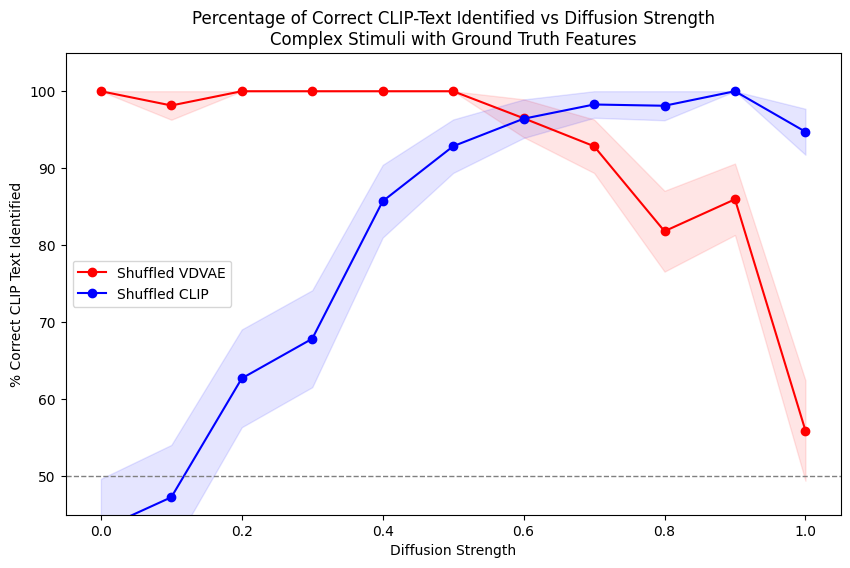

In [6]:
from scipy.stats import sem

stimuli_df = filtered_df[(filtered_df['sample'] >= 6) & (filtered_df['sample'] < 12)]
# Group by 'strength' and 'experiment', and calculate the mean and SEM of 'picked_target'
grouped_df = stimuli_df.groupby(['strength', 'experiment'])['picked_target'].agg(['mean', sem]).reset_index()

# Convert the mean to percentage
grouped_df['picked_target_percentage'] = grouped_df['mean'] * 100
grouped_df['sem_percentage'] = grouped_df['sem'] * 100

# Create the plot
plt.figure(figsize=(10, 6))

# Plot the line
plt.plot(grouped_df[grouped_df['experiment'] == 1]['strength'], 
         grouped_df[grouped_df['experiment'] == 1]['picked_target_percentage'], 
         '-o', 
         label='Shuffled VDVAE', 
         color='red')
# Fill the area between the lines
plt.fill_between(grouped_df[grouped_df['experiment'] == 1]['strength'], 
                 grouped_df[grouped_df['experiment'] == 1]['picked_target_percentage'] - grouped_df[grouped_df['experiment'] == 1]['sem_percentage'], 
                 grouped_df[grouped_df['experiment'] == 1]['picked_target_percentage'] + grouped_df[grouped_df['experiment'] == 1]['sem_percentage'], 
                 color='red', 
                 alpha=0.1)

plt.plot(grouped_df[grouped_df['experiment'] == 2]['strength'], 
         grouped_df[grouped_df['experiment'] == 2]['picked_target_percentage'], 
         '-o', 
         label='Shuffled CLIP', 
         color='blue')

# Fill the area between the lines
plt.fill_between(grouped_df[grouped_df['experiment'] == 2]['strength'], 
                 grouped_df[grouped_df['experiment'] == 2]['picked_target_percentage'] - grouped_df[grouped_df['experiment'] == 2]['sem_percentage'], 
                 grouped_df[grouped_df['experiment'] == 2]['picked_target_percentage'] + grouped_df[grouped_df['experiment'] == 2]['sem_percentage'], 
                 color='blue', 
                 alpha=0.1)


# Adding labels and title
plt.xlabel('Diffusion Strength')
plt.ylabel('% Correct CLIP Text Identified')
# Set the y-axis limits
plt.axhline(y=50, color='gray', linestyle='--', linewidth=1)
plt.ylim(45, 105)
plt.title('Percentage of Correct CLIP-Text Identified vs Diffusion Strength\nComplex Stimuli with Ground Truth Features')
plt.legend()

# Show the plot
plt.show()

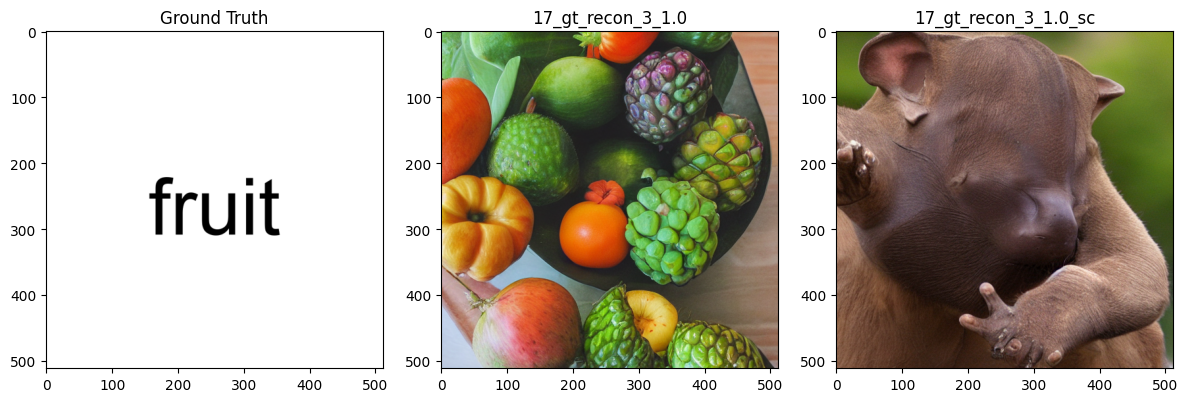

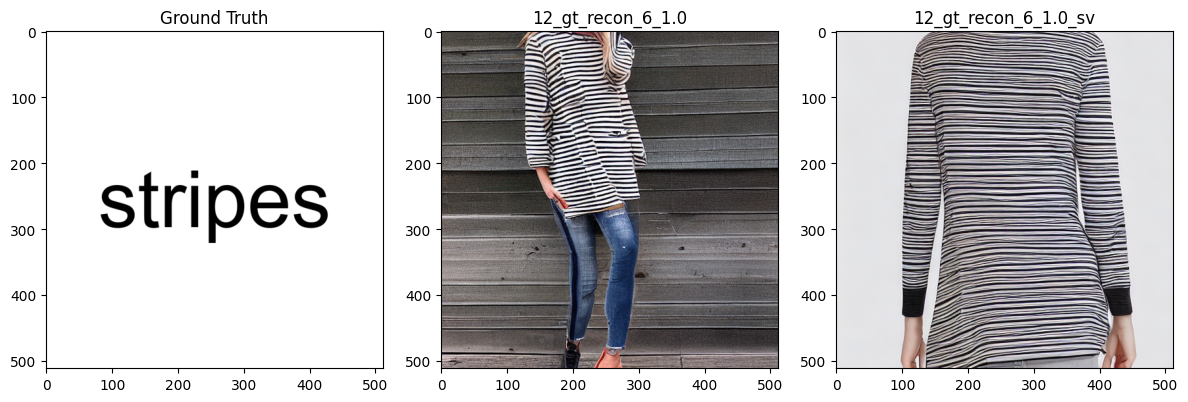

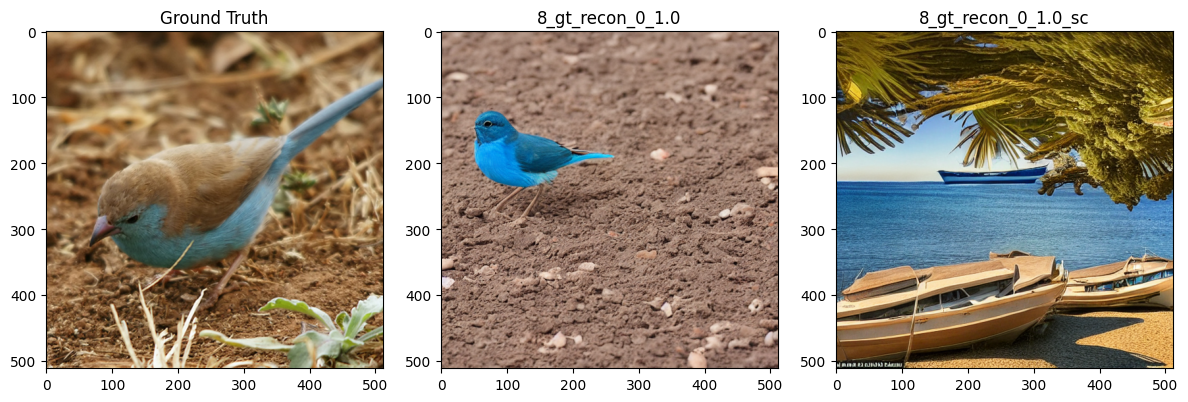

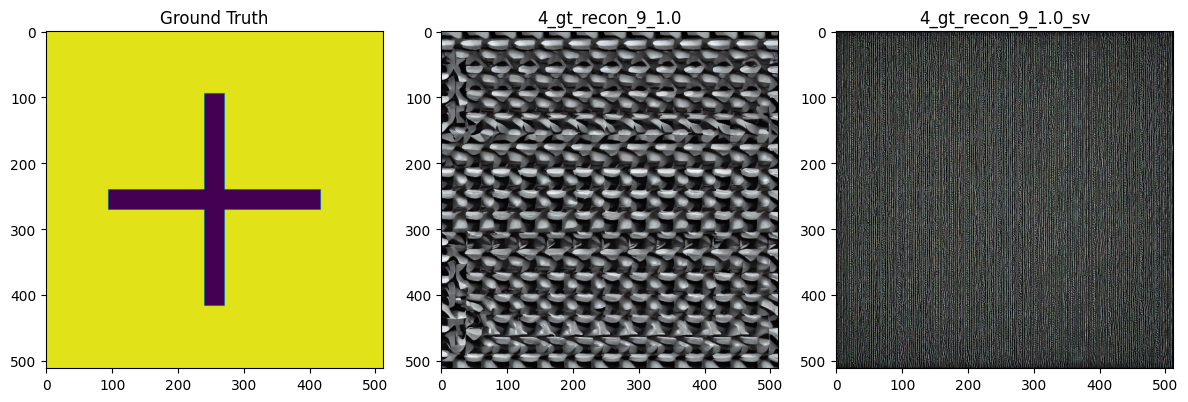

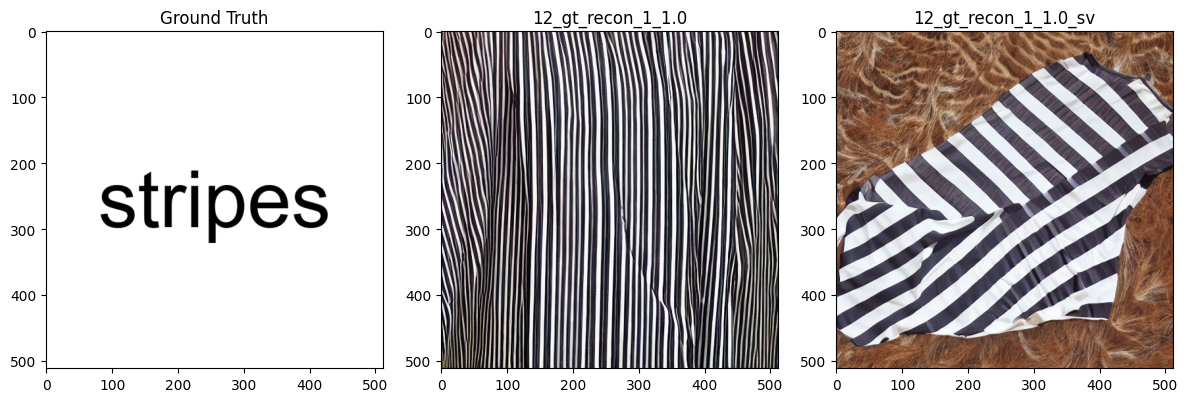

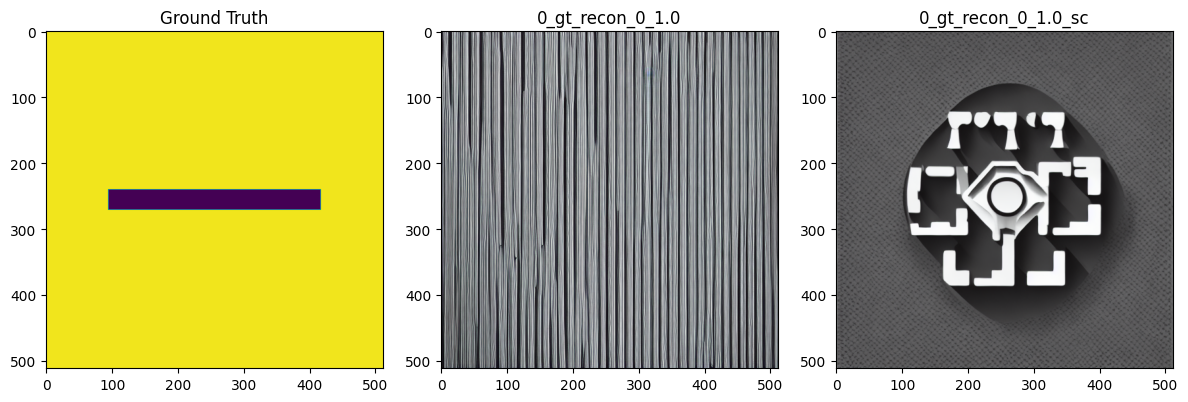

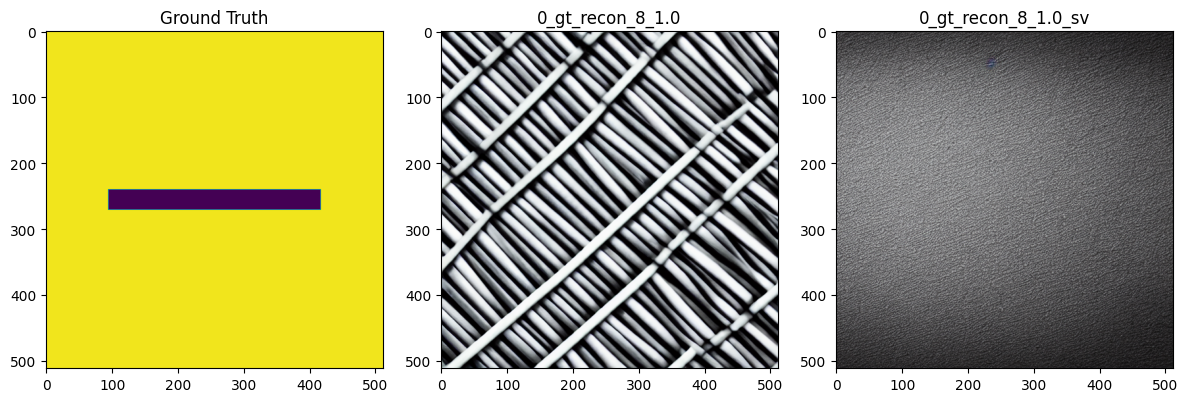

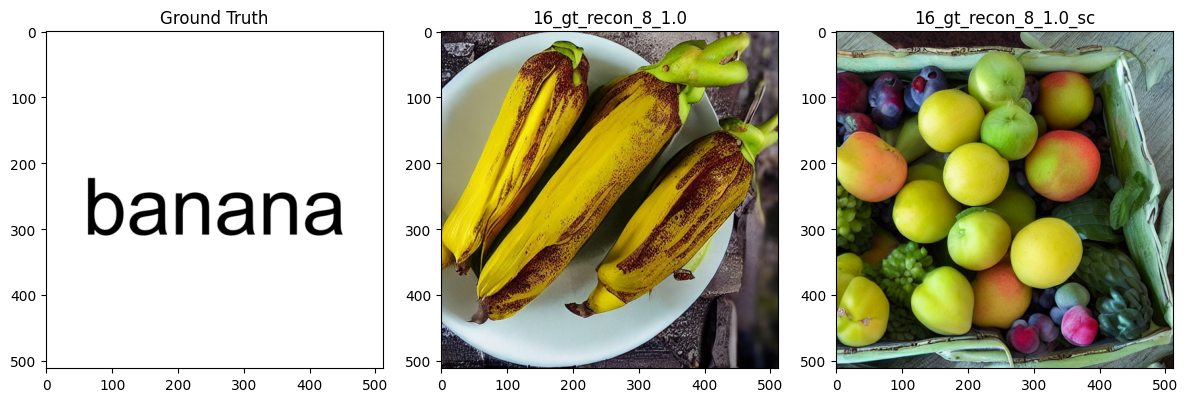

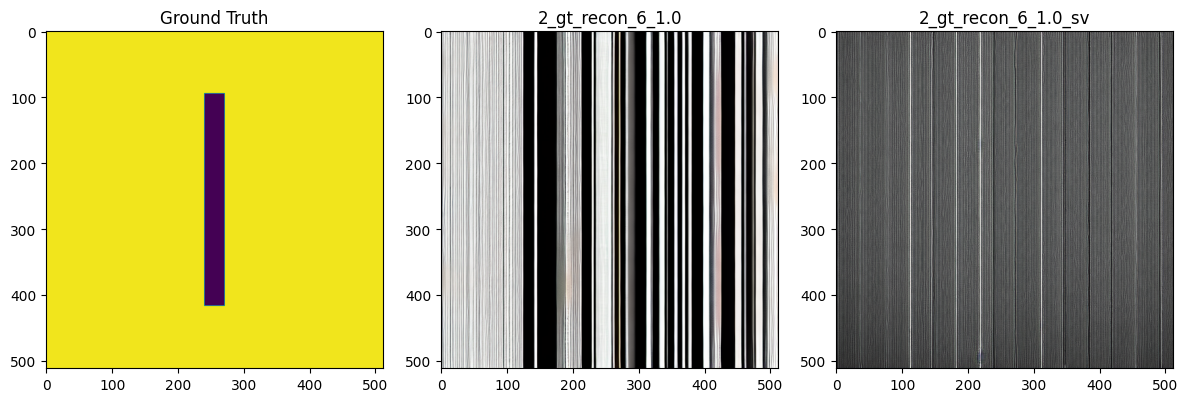

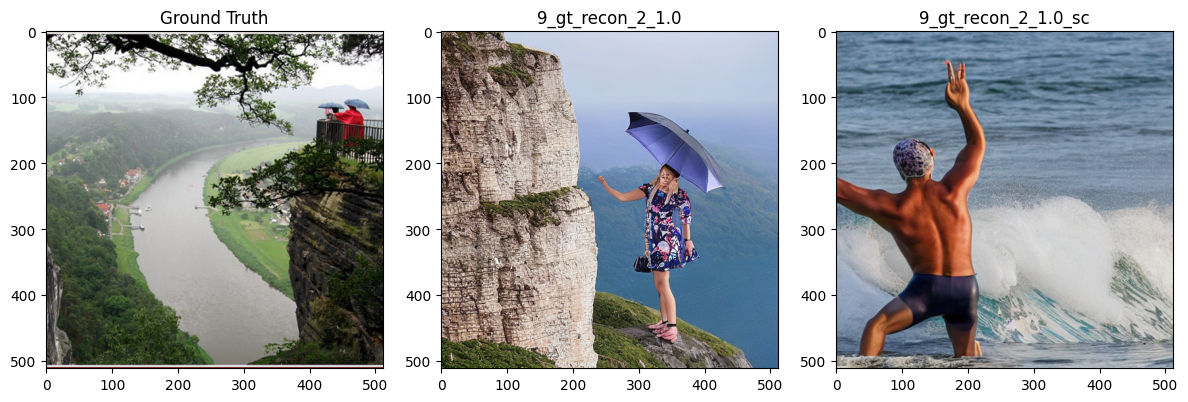

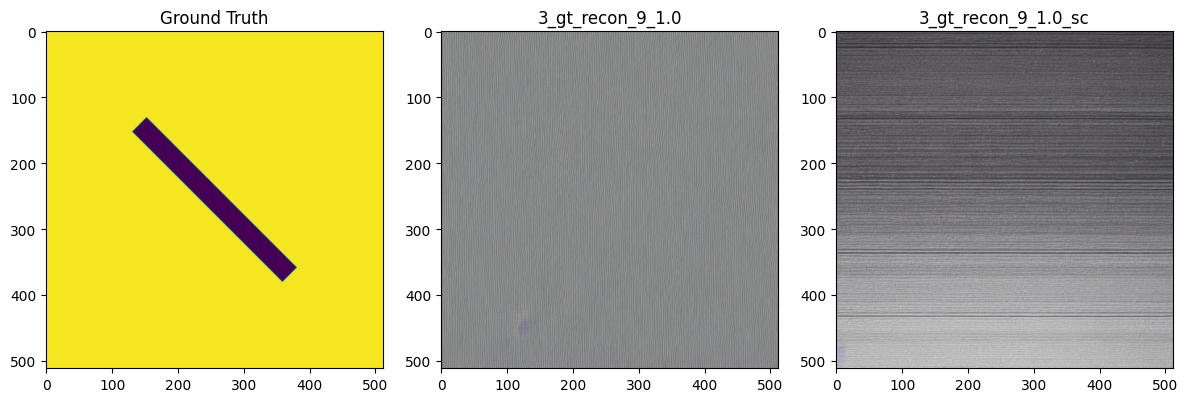

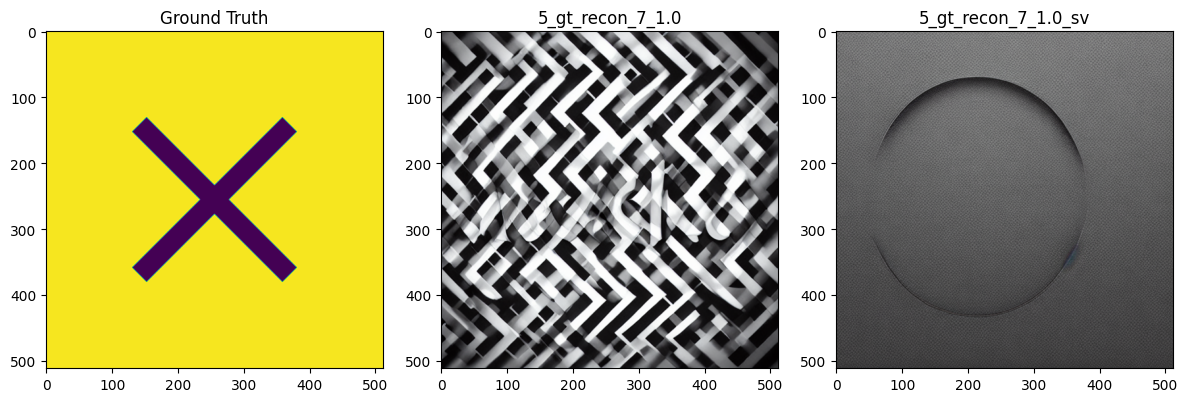

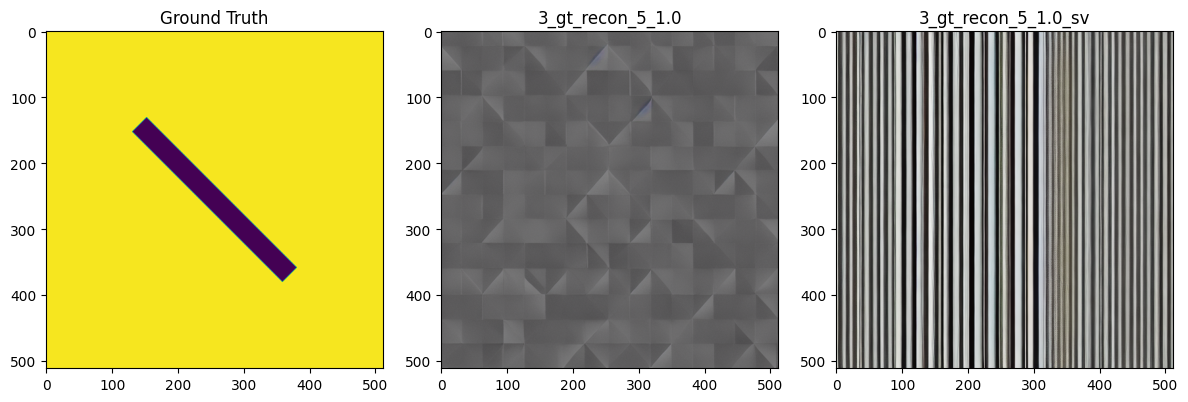

In [26]:

strength1 = filtered_df[filtered_df['strength'] == 1.0]
strength1.head()

# Iterate over the first 20 rows of strength1 dataframe
for i, (_, row) in enumerate(strength1.iterrows()):
    gt = row['stim1']
    stims = [row['stim2'], row['stim3']]
    if not row['target_on_left']:
        stims.reverse()
    
    # Create a 1x3 grid of subplots
    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    # Plot the ground truth
    axs[0].imshow(Image.open(f"stimuli_v1/{gt}.png"))
    axs[0].set_title('Ground Truth')

    # Plot the stimuli
    for j, stim in enumerate(stims):
        axs[j + 1].imshow(Image.open(f"stimuli_v1/{stim}.png"))
        axs[j + 1].set_title(stim)

    # Adjust the spacing between subplots
    plt.tight_layout()

    # Display the plot
    plt.show()

    if i == 19:
        break

In [11]:

# Iterate over each experiment
experiment = 1
for mode in ["vision", "imagery"]:
    
    print(f"Mode: {mode}")
    for stimtype in ["simple", "complex"]:
        print(f"Stimtype: {stimtype}")
        # Filter the data for the current method, mode, and experiment
        df_trial_exp1 = df_trial_exp[(df_trial_exp['method'] != "takagi") & (df_trial_exp['method'] != "mindeye2") & (df_trial_exp['experiment'] == experiment) & (df_trial_exp['mode'] == mode) & (df_trial_exp['stimtype'] == stimtype)]
        # Perform a binomial test
        # The null hypothesis is that the probability of success is 0.5 (chance level)
        p_value = binomtest(df_trial_exp1['picked_target'].sum(), n=len(df_trial_exp1['picked_target']), p=0.5, alternative='two-sided').pvalue

        print("Number of experiment trials:", len(df_trial_exp1))
        print("Success rate: ", len(df_trial_exp1[df_trial_exp1["picked_target"]]) / len(df_trial_exp1))
        print(f'P-value: {p_value}')
        
        print("--------------------")
        print()


Mode: vision
Stimtype: simple
Number of experiment trials: 1180
Success rate:  0.7254237288135593
P-value: 8.186063399887696e-56
--------------------

Stimtype: complex
Number of experiment trials: 1185
Success rate:  0.8286919831223629
P-value: 7.073258575680375e-123
--------------------

Mode: imagery
Stimtype: simple
Number of experiment trials: 1185
Success rate:  0.6649789029535865
P-value: 2.795007020162622e-30
--------------------

Stimtype: complex
Number of experiment trials: 1190
Success rate:  0.7352941176470589
P-value: 2.3051714461153325e-61
--------------------



In [ ]:
import matplotlib.pyplot as plt

# Calculate the average similarity and confidence for each method and stimtype
averages = []
for method in df_trial_exp2['method'].unique():
    # for stimtype in df_trial_exp2['stimtype'].unique():
    category_df = df_trial_exp2[(df_trial_exp2["method"] == method) & (df_trial_exp2["stimtype"] == stimtype)]
    avg_vision_similarity = category_df['target_similarity'].mean()
    avg_imagery_similarity = category_df['distractor_similarity'].mean()
    avg_vision_confidence = category_df['target_confidence'].mean()
    avg_imagery_confidence = category_df['distractor_confidence'].mean()
    print(f"Method: {method}, Average Vision Similarity: {avg_vision_similarity:.3f}, Average Vision Confidence: {avg_vision_confidence:.3f}, Average Imagery Similarity: {avg_imagery_similarity:.3f}, Average Imagery Confidence: {avg_imagery_confidence:.3f}")
    averages.append((method, stimtype, avg_vision_similarity, avg_imagery_similarity))

# Create a list of methods and their corresponding average similarity values for vision and imagery
methods = []
vision_similarities = []
imagery_similarities = []

for method, _, avg_vision_similarity, avg_imagery_similarity in averages:
    if method == "boi-v2.1":
        method_label = "mindeye\n + BOI"
    elif method == "boi-v2.3":
        method_label = "braindiffuser\n + BOI"
    else:
        method_label = method
    methods.append(method_label)
    vision_similarities.append(avg_vision_similarity)
    imagery_similarities.append(avg_imagery_similarity)

# Set the width of the bars
bar_width = 0.35

# Set the positions of the bars on the X-axis
r1 = np.arange(len(methods))
r2 = [x + bar_width for x in r1]

# Plot the bars
plt.bar(r1, vision_similarities, color='blue', width=bar_width, label='Vision')
plt.bar(r2, imagery_similarities, color='orange', width=bar_width, label='Imagery')

# Add labels and title
plt.xlabel('Methods')
plt.ylabel('Average Similarity')
plt.title('Experiment 2: Average Similarity for Vision and Imagery')
plt.xticks([r + bar_width/2 for r in range(len(methods))], methods)

# Add legend
plt.legend()

# Show the plot
plt.show()



In [ ]:
# Experiment 3 is brain-optimized inference vs base model, BOI trials are marked as "target", base trials are marked as "distractor"

df_trial_exp3 = df_trial_exp[(df_trial_exp['experiment'] == 3)]
print(df_trial_exp3['method'].unique())
for method in df_trial_exp3['method'].unique():
    for mode in df_trial_exp3['mode'].unique():
        category_df = df_trial_exp3[(df_trial_exp3["mode"] == mode) & (df_trial_exp3["method"] == method)]
        avg_boi_similarity = category_df['target_similarity'].mean()
        avg_base_similarity = category_df['distractor_similarity'].mean()
        avg_boi_confidence = category_df['target_confidence'].mean()
        avg_base_confidence = category_df['distractor_confidence'].mean()
        print(f"Method: {method}, Mode: {mode}, Average BOI Similarity: {avg_boi_similarity:.3f}, Average BOI Confidence: {avg_boi_confidence:.3f}, Average Base Model Similarity: {avg_base_similarity:.3f}, Average Base Model Confidence: {avg_base_confidence:.3f}")

import matplotlib.pyplot as plt

# Data
methods = df_trial_exp3['method'].unique()
modes = df_trial_exp3['mode'].unique()
avg_boi_similarity = []
avg_base_similarity = []
avg_boi_confidence = []
avg_base_confidence = []

# Calculate averages
for method in methods:
    for mode in modes:
        category_df = df_trial_exp3[(df_trial_exp3["mode"] == mode) & (df_trial_exp3["method"] == method)]
        avg_boi_similarity.append(category_df['target_similarity'].mean())
        avg_base_similarity.append(category_df['distractor_similarity'].mean())
        avg_boi_confidence.append(category_df['target_confidence'].mean())
        avg_base_confidence.append(category_df['distractor_confidence'].mean())

# Plotting
x = range(len(methods) * len(modes))
width = 0.35

fig, ax = plt.subplots()
rects1 = ax.bar(x, avg_boi_similarity, width, label='BOI Similarity')
rects2 = ax.bar([i + width for i in x], avg_base_similarity, width, label='Base Model Similarity')

# Add labels, title, and legend
ax.set_ylabel('Average Similarity')
ax.set_title('Experiment 3: BOI vs Base Model Similarity')
ax.set_xticks([i + width/2 for i in x])
ax.set_xticklabels([f'{method}\n{mode}' for method in methods for mode in modes])
ax.legend()

# Show the plot
plt.show()


In [ ]:
      mode    base method  Statistic   P-value  Avg_Percentage_Improvement_Corrected  
0  imagery  braindiffuser   4.852082  0.000002   28.047254%
1  imagery        mindeye  -0.167633  0.866943   -0.796622%
2   vision  braindiffuser   3.475545  0.000557   15.967266% 
3   vision        mindeye   1.740338  0.082451   5.790017%
